# 🎒 Sistem Rekomendasi Perlengkapan Outdoor (Camp Equipment)
## Modul 2: Analisis Material Teknis, Segmentasi Harga, & Starter Pack Knapsack Optimizer

> **Status Pembaruan:** Notebook ini telah diperbarui untuk membaca **Dataset Terstandarisasi (`gear_equipment_cleaned.csv`)**. Seluruh harga telah berupa angka pasti (*integer*), dilengkapi fitur kapasitas tenda (*1P/2P*) dan label teknologi bahan (*Is_Ultralight*).

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

# Deteksi path dataset gear bersih
candidate_paths = [
    os.path.join('..', 'data', 'gear_equipment_cleaned.csv'),
    os.path.join('data', 'gear_equipment_cleaned.csv'),
    'gear_equipment_cleaned.csv'
]
PATH_GEAR = next((p for p in candidate_paths if os.path.exists(p)), None)
print(f'✅ Membaca data bersih dari: {PATH_GEAR}')

df_gear = pd.read_csv(PATH_GEAR, encoding='utf-8')
print(f'Total Item Perlengkapan: {len(df_gear)} produk')
df_gear.head(3)

✅ Membaca data bersih dari: ..\data\gear_equipment_cleaned.csv
Total Item Perlengkapan: 49 produk


,Kategori,Nama,Harga_Rp,Tier_Harga,Is_Ultralight,Kapasitas_Tenda,Material,Ukuran,Link_Toko
0,Tenda,Naturehike Cloud Up 2,1600000,High-End / Ultralight (>1.5jt),1,2 Orang,"Nylon 20D , frame alloy",2p,Link tersedia di marketplace
1,Tenda,Decathlon MH100,500000,Mid-Range (100k-500k),0,2 Orang,"Polyester 210t , frame fiber",2p,Link tersedia di marketplace
2,Tenda,Wildshell Navageo,750000,Premium (500k-1.5jt),1,2 Orang,"Polyester 210t , frame alloy",2p,Link tersedia di marketplace


### 1. Eksplorasi Harga & Distribusi Material

Statistik Harga Bersih per Kategori:
             Jumlah Item    Min (Rp) Median (Rp)      Max (Rp)
Kategori                                                      
Aksesoris           Rp 7       Rp 20    Rp 7,000     Rp 90,000
Carrier             Rp 6      Rp 285  Rp 170,227    Rp 450,000
Cooking Set         Rp 8   Rp 39,000   Rp 80,000    Rp 180,000
Lampu               Rp 4      Rp 140   Rp 37,500    Rp 260,000
Matras              Rp 5   Rp 30,000  Rp 180,000    Rp 290,000
Meja Kursi          Rp 3  Rp 108,000  Rp 159,000    Rp 166,000
Sleeping Bag        Rp 6        Rp 8  Rp 215,000    Rp 500,000
Tenda              Rp 10  Rp 180,000  Rp 667,000  Rp 1,600,000


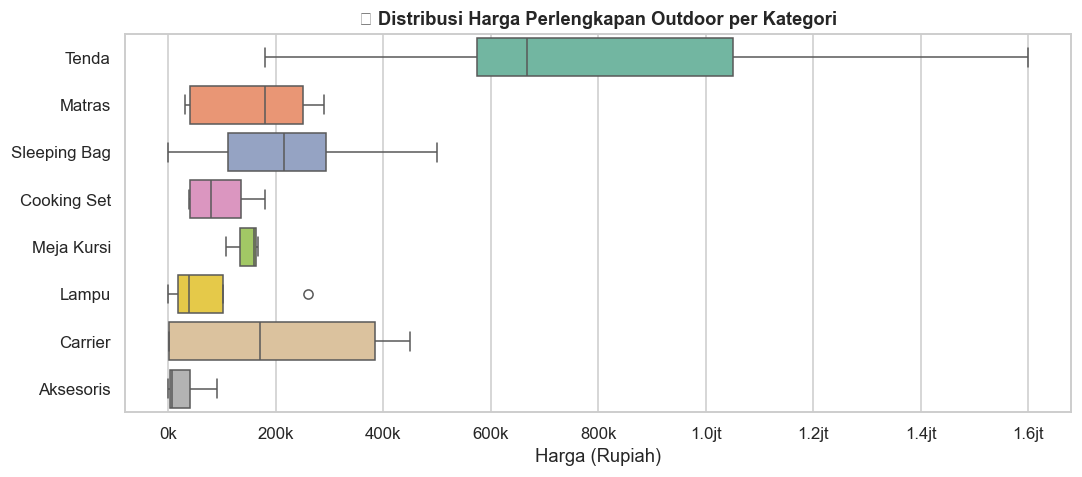

In [2]:
print("Statistik Harga Bersih per Kategori:")
stats = df_gear.groupby('Kategori')['Harga_Rp'].agg(['count', 'min', 'median', 'max'])
stats.columns = ['Jumlah Item', 'Min (Rp)', 'Median (Rp)', 'Max (Rp)']
print(stats.applymap(lambda x: f'Rp {int(x):,}' if isinstance(x, (int, float)) else x))

# Boxplot Harga per Kategori
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df_gear, x='Harga_Rp', y='Kategori', palette='Set2')
plt.gca().xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x/1000)}k' if x < 1000000 else f'{x/1000000:.1f}jt'))
plt.title('💸 Distribusi Harga Perlengkapan Outdoor per Kategori', fontsize=12, fontweight='bold')
plt.xlabel('Harga (Rupiah)')
plt.ylabel('')
plt.tight_layout()
plt.show()

### 2. Algoritma Starter Pack Optimizer (0/1 Knapsack Problem)

> Algoritma ini memastikan pembelian 4 barang esensial (**Tenda + Sleeping Bag + Matras + Kompor**) tidak melebihi anggaran, serta memperhitungkan kapasitas tenda.

In [3]:
def cari_rekomendasi_gear(kategori='', kapasitas_tenda='', gaya='semua', max_harga=None, top_n=5):
    df = df_gear[df_gear['Harga_Rp'].notna()].copy()
    
    if kategori:
        df = df[df['Kategori'].str.lower().str.contains(kategori.lower())]
    if kapasitas_tenda:
        df = df[df['Kapasitas_Tenda'].str.contains(kapasitas_tenda)]
    if max_harga is not None:
        df = df[df['Harga_Rp'] <= max_harga]
        
    if gaya == 'ultralight':
        df = df.sort_values(by=['Is_Ultralight', 'Harga_Rp'], ascending=[False, True])
    else:
        df = df.sort_values(by='Harga_Rp', ascending=True)
        
    print('=' * 75)
    print(f'🎒 REKOMENDASI PEMBELIAN GEAR: Kategori="{kategori or "Semua"}"')
    print('=' * 75)
    for i, (_, r) in enumerate(df.head(top_n).iterrows(), 1):
        tag = '⚡ ULTRALIGHT' if r['Is_Ultralight'] == 1 else '⛺ STANDAR'
        print(f"{i}. {r['Nama']} [{tag}]")
        print(f"   Kategori : {r['Kategori']} | Kapasitas: {r['Kapasitas_Tenda']}")
        print(f"   Material : {r['Material']}")
        print(f"   Harga    : Rp {int(r['Harga_Rp']):,} ({r['Tier_Harga']})")
        print(f"   Link     : {r['Link_Toko']}")
        print('-' * 75)

def buat_paket_starter_pack(budget_total=1500000, kapasitas_tenda='2 Orang', gaya='hemat'):
    kategori_wajib = ['Tenda', 'Sleeping Bag', 'Matras', 'Cooking Set']
    total_biaya = 0
    paket = []
    
    print('=' * 75)
    print(f'📦 STARTER PACK OPTIMIZER (Budget: Rp {budget_total:,} | Target: Tenda {kapasitas_tenda})')
    print('=' * 75)
    
    for kat in kategori_wajib:
        sub = df_gear[df_gear['Kategori'] == kat].copy()
        if kat == 'Tenda' and kapasitas_tenda:
            sub = sub[sub['Kapasitas_Tenda'] == kapasitas_tenda]
            
        if gaya == 'ultralight':
            sub = sub.sort_values(by=['Is_Ultralight', 'Harga_Rp'], ascending=[False, True])
        else:
            sub = sub.sort_values(by='Harga_Rp', ascending=True)
            
        if not sub.empty:
            item = sub.iloc[0]
            total_biaya += item['Harga_Rp']
            paket.append(item)
            print(f"✓ {kat:<15} : {item['Nama']:<30} Rp {int(item['Harga_Rp']):>10,} [{item['Material']}]")
            
    print('-' * 75)
    print(f"TOTAL ESTIMASI BIAYA : Rp {int(total_biaya):,}")
    sisa = budget_total - total_biaya
    if sisa >= 0:
        print(f"SISA SALDO HEMAT     : Rp {int(sisa):,} (Bisa untuk gas, lampu, & logistik)")
    else:
        print(f"OVER BUDGET          : Rp {int(abs(sisa)):,} (Disarankan pilih tier di bawahnya)")
    print('=' * 75)

print('✅ Fungsi cari_rekomendasi_gear() & buat_paket_starter_pack() siap digunakan!')

✅ Fungsi cari_rekomendasi_gear() & buat_paket_starter_pack() siap digunakan!


### 3. Demonstrasi Starter Pack Optimizer

In [4]:
# Uji Kasus 1: Paket Hemat untuk Tenda Kapasitas 2 Orang (Budget Rp 1.500.000)
buat_paket_starter_pack(budget_total=1500000, kapasitas_tenda='2 Orang', gaya='hemat')

📦 STARTER PACK OPTIMIZER (Budget: Rp 1,500,000 | Target: Tenda 2 Orang)
✓ Tenda           : Decathlon MH100                Rp    500,000 [Polyester 210t , frame fiber]
✓ Sleeping Bag    : bulang meikha                  Rp          8 [nan]
✓ Matras          : Matras Karet Biasa             Rp     30,000 [Karet]
✓ Cooking Set     : Windshiled Hewolf 3000         Rp     39,000 [Stainless Steel]
---------------------------------------------------------------------------
TOTAL ESTIMASI BIAYA : Rp 569,008
SISA SALDO HEMAT     : Rp 930,992 (Bisa untuk gas, lampu, & logistik)


In [5]:
# Uji Kasus 2: Paket Prioritas Bahan Ultralight (Budget Rp 2.500.000)
buat_paket_starter_pack(budget_total=2500000, kapasitas_tenda='2 Orang', gaya='ultralight')

📦 STARTER PACK OPTIMIZER (Budget: Rp 2,500,000 | Target: Tenda 2 Orang)
✓ Tenda           : LWY compass                    Rp    650,000 [Polyester 210t , frame alloy, 1.9 kg]
✓ Sleeping Bag    : Baseking Bulang                Rp    500,000 [Bulu angsa (FP 800, FW 320)]
✓ Matras          : Matras Karet Biasa             Rp     30,000 [Karet]
✓ Cooking Set     : Kompor Canister BRS3000T       Rp    180,000 [Titanium]
---------------------------------------------------------------------------
TOTAL ESTIMASI BIAYA : Rp 1,360,000
SISA SALDO HEMAT     : Rp 1,140,000 (Bisa untuk gas, lampu, & logistik)
